# Unified AR tuning experiments — fixed path, repeated paths and Jones-sampled models

This notebook implements **experiments 1, 2 and 3** under **Tuning experiments** in the [AR thesis chapter](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex): first one fixed AR(3) path, then a configurable number of fresh realizations with the same coefficients. Experiment 3 draws fresh coefficient vectors using Jones’s method and simulates one path for each vector. All three experiments use one common fixed starting direction and compare absolute and diameter-normalized geometric steps.

For experiments 1 and 2, the fixed model is $X_t=0.6X_{t-1}-0.3X_{t-2}+0.2X_{t-3}+\varepsilon_t$, with $T=500$ and independent $\varepsilon_t\sim U(-1,1)$. The same coefficient vector appears in [Arbúes et al. (2013), §5.3, p. 13, with $b=0$](https://www.ucm.es/data/cont/docs/518-2013-11-05-Arbues_Feb19.pdf#page=13). It is a simulation precedent for the coefficients; the innovation choice here follows the thesis.

**Dimension convention:** newest-first windows have $k=p+1=4$ coordinates, so the starting direction is on $S^3$. The thesis currently writes $S^2$ in this paragraph; this notebook uses the four-dimensional embedding and does not edit the thesis.

The optimizer and grid search live in shared modules: [descent.py](../ar_tools/descent.py) and [tuning.py](../ar_tools/tuning.py). Each displayed figure is also exported as PDF and PNG. Experiment 1 selects the smallest achieved minimum width. Experiment 2 selects the smallest mean achieved minimum width across realizations. Coefficient diagnostics do not enter selection.

A final win-frequency comparison awards +1 to every configuration whose achieved minimum empirical width is within an absolute tolerance $\varepsilon=10^{-8}$ of the best achieved value on each realization. The mean-width and win-count rankings are both shown.
All three experiments use a **2,000-iteration cap and patience 200**.


In [1]:
import hashlib
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

AR_CODE_DIR = next(
    candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root / "Code" / "Code_AR_processes", root)
    if (candidate / "ar_tools/functions.py").is_file()
)
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Refresh the optimizer as well as the tuner in an existing notebook kernel.
from Code.Code_AR_processes.ar_tools import descent as descent_tools
descent_tools = importlib.reload(descent_tools)
from Code.Code_AR_processes.ar_tools.functions import is_stationary, simulate_uniform_ar, sliding_window_point_cloud
# Refresh the local tuning helpers when setup is rerun in an existing kernel.
from Code.Code_AR_processes.ar_tools import tuning as tuning_tools
tuning_tools = importlib.reload(tuning_tools)
from Code.Code_AR_processes.ar_tools.tuning import (
    tune_geometric_half_life_schedules, tune_fixed_ar_realizations, tune_jones_ar_realizations,
    summarize_configuration_wins,
)
with plt.rc_context():
    from Code.Code_AR_processes.ar_tools.plotting_functions import save_figure
    from Code.Code_AR_processes.ar_tools.tuning_plots import plot_tuning_matrices

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42})
np.set_printoptions(precision=8, suppress=True)
EXPERIMENT_NAME = "ar_unified_tuning_experiments"
OUTPUT_ROOT = AR_CODE_DIR / "outputs"

Matplotlib created a temporary cache directory at /var/folders/tr/kt47kz8d61ngpcfl5d_s9fc80000gn/T/matplotlib-isbc8c30 because the default path (/Users/iljasukhanov/.matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


## Fixed settings and tuning grids

The grid is exactly $H\in\{2,5,10,20,50,100,200,1000\}$ and $s\in\{0.1,0.2,\ldots,0.9\}$, with $\beta=2^{-1/H}$. For the absolute rule $s=\gamma_0$; for the normalized rule $s=c$ and $\gamma_0=c/L$.

All three experiments use a **2,000-iteration cap and patience 200**. `improvement_tolerance=0` records every strictly smaller width and resets the patience counter. The win-frequency comparison awards +1 to every configuration whose achieved width is at most the best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). The simulator discards 2,000 burn-in observations, a retained convention from the previous tuning notebook. Seeds and burn-in are explicit experimental settings, not fitted parameters. [Thesis: termination and tuning paragraphs](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex), [simulation](../ar_tools/functions.py), [stopping rule](../ar_tools/descent.py).

Set **`number_of_realizations`** in the next cell to choose the number of independent paths in experiment 2 (default: **100**). The simulation, ranking, summaries and plots of achieved widths all use this setting.


In [2]:
T = 500
p = 3
phi = np.array([0.6, -0.3, 0.2], dtype=float)
burnin = 2_000
process_seed = 20261018
optimizer_seed = 20261019
embedding_dimension = p + 1

max_iterations = 2_000
patience = 200
improvement_tolerance = 0.0
scale_grid = np.arange(1, 10) / 10.0  # 0.1, 0.2, ..., 0.9
half_life_grid = np.array([2, 5, 10, 20, 50, 100, 200, 1000])

number_of_realizations = 100  # CHANGE THIS: number of independent paths in experiment 2.
realization_process_seed = 20261020

epsilon_win_tolerance = 1e-8  # CHANGE THIS: absolute distance from each path's best achieved width.

if p != 3 or phi.shape != (p,) or embedding_dimension != 4:
    raise ValueError("This experiment requires an AR(3) model and four-coordinate windows.")
stationary, companion_eigenvalues = is_stationary(phi)
if not stationary or phi[-1] == 0:
    raise ValueError("Choose a causal AR(3) coefficient vector with nonzero phi_3.")
if T < embedding_dimension + 1 or burnin < 0:
    raise ValueError("Use enough observations to form at least two windows and nonnegative burn-in.")

if (isinstance(number_of_realizations, (bool, np.bool_))
        or not isinstance(number_of_realizations, (int, np.integer))
        or number_of_realizations < 1):
    raise ValueError("number_of_realizations must be a positive integer.")

## Simulate once and fix the starting direction

Every candidate reuses the identical `point_cloud` and `initial_direction`. The cloud consists of $(X_t,X_{t-1},X_{t-2},X_{t-3})$, $t=4,\ldots,T$, giving 497 windows with the default settings. One standard Gaussian four-vector is normalized to obtain the fixed random direction; this is the same initialization construction used by the [shared descent implementation](../ar_tools/descent.py).


In [3]:
series = simulate_uniform_ar(phi, sample_size=T, burnin=burnin, half_width=1.0, rng=process_seed)
point_cloud = sliding_window_point_cloud(series, embedding_dimension)
initial_direction = np.random.default_rng(optimizer_seed).normal(size=embedding_dimension)
initial_direction /= np.linalg.norm(initial_direction)
if point_cloud.shape != (T - p, embedding_dimension) or not np.all(np.isfinite(point_cloud)):
    raise RuntimeError("Invalid embedding cloud.")

configuration = {
    "experiment": "fixed_path_and_fixed_phi_realizations", "T": int(T), "p": int(p), "phi": phi.tolist(),
    "burnin": int(burnin), "innovation_distribution": "Uniform(-1,1)",
    "process_seed": int(process_seed), "optimizer_seed": int(optimizer_seed),
    "initial_direction": initial_direction.tolist(), "starts": 1,
    "max_iterations": int(max_iterations), "stopping": "iteration_limit_or_patience", "patience": int(patience),
    "improvement_tolerance": float(improvement_tolerance),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "step_rules": ["absolute", "diameter_normalized"],
    "lipschitz_rule": "exact Euclidean diameter of the full empirical cloud",
    "selection": "smallest recorded empirical width; ties: evaluations, actual gamma0, beta, rule",
    "point_cloud_sha256": hashlib.sha256(np.ascontiguousarray(point_cloud).tobytes()).hexdigest(),
    "experiment_2": {"replications": int(number_of_realizations),
                     "process_seed": int(realization_process_seed),
                     "selection": "smallest mean achieved minimum width; ties: mean evaluations, rule, scale, H"},
    "win_frequency": {"score": "minimum_width", "credit": "one_per_absolute_gap_qualifier",
                      "epsilon": float(epsilon_win_tolerance)},
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py"]
    )).hexdigest(),
}
run_id = hashlib.sha256(repr(sorted(configuration.items())).encode()).hexdigest()[:16]
PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / run_id
IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / run_id
for directory in (PDF_DIR, IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Run {run_id}: {point_cloud.shape[0]} windows, one fixed starting direction")
print(f"True coefficients: {phi}; companion spectral radius: {np.max(np.abs(companion_eigenvalues)):.8f}")
print(f"Fixed starting direction: {initial_direction}")

Run e5d3a96d1d49f6bd: 497 windows, one fixed starting direction
True coefficients: [ 0.6 -0.3  0.2]; companion spectral radius: 0.62876280
Fixed starting direction: [ 0.0469043  -0.81156153  0.31282302  0.49123275]


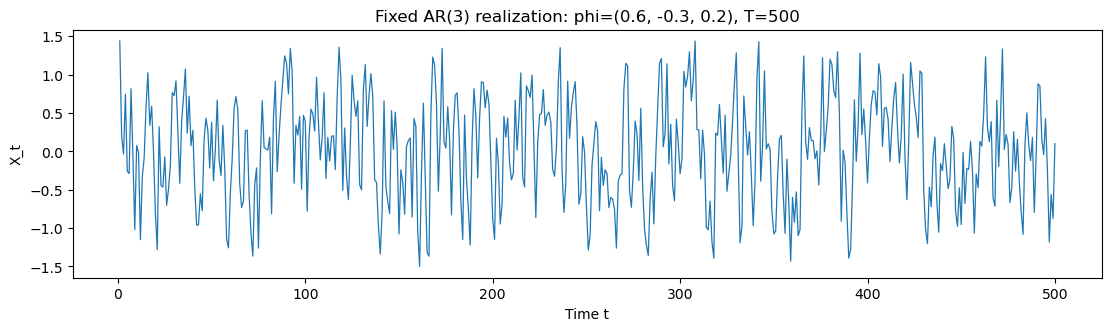

In [4]:
# dont I have a unified function for plotting an ar process?

fig, ax = plt.subplots(figsize=(11, 3.2), constrained_layout=True)
ax.plot(np.arange(1, T + 1), series, lw=0.9)
ax.set(xlabel="Time t", ylabel="X_t", title=f"Fixed AR(3) realization: phi={tuple(phi)}, T={T}")
save_figure(fig, "01_fixed_process", pdf_directory=PDF_DIR, image_directory=IMAGE_DIR)
plt.show()
plt.close(fig)


## Run both grids on the same cloud and start

Compare 72 pairs per rule, 144 labeled candidates in total:

$$\gamma_t=s\,2^{-t/H}\quad\text{(absolute)},\qquad
\gamma_t=\frac{s}{L}\,2^{-t/H}\quad\text{(diameter normalized)}.$$

Here $L=\max_{i,j}\|P_i-P_j\|_2$ is the **actual point-cloud diameter**, as specified in the thesis. The implementation is [tuning.py, `tune_geometric_half_life_schedules`](../ar_tools/tuning.py).

For this one fixed cloud, the two rules are algebraic reparameterizations: $c=L\gamma_0$. The same numerical scale grid searches different actual step-size ranges. A width difference between these grids therefore measures their finite search ranges, not an intrinsic advantage of normalization. Effective schedules that coincide are computed once by the shared tuner.

Selection uses the smallest width recorded over the trajectory, including its starting direction. True coefficients are used only afterward for coefficient-recovery diagnostics.


In [5]:
tuning_result = tune_geometric_half_life_schedules(
    point_cloud, initial_direction, scale_grid, half_life_grid,
    iterations=max_iterations, patience=patience,
    improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed,
    progress=True,
)
L = tuning_result["diameter"]
ranking = pd.DataFrame(tuning_result["candidates"]).sort_values(
    ["minimum_width", "total_evaluations", "gamma0", "beta", "step_rule"], kind="stable",
).reset_index(drop=True)
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
# Coefficients are calculated only after selecting by width.
direction_values = ranking[[f"u_{j}" for j in range(embedding_dimension)]].to_numpy()
valid = np.abs(direction_values[:, 0]) > 1e-10
estimated_coefficients = np.full((len(ranking), p), np.nan)
np.divide(-direction_values[:, 1:], direction_values[:, :1],
          out=estimated_coefficients, where=valid[:, None])
for j in range(p):
    ranking[f"estimated_phi_{j+1}"] = estimated_coefficients[:, j]
ranking["coefficient_error_l2"] = np.linalg.norm(estimated_coefficients - phi, axis=1)
ranking["coefficient_valid"] = valid & np.all(np.isfinite(estimated_coefficients), axis=1)
ranking["last_recorded_step"] = ranking["gamma0"] * ranking["beta"] ** (ranking["total_evaluations"] - 1)
ranking["on_grid_edge"] = (
    ranking["step_value"].isin([float(scale_grid.min()), float(scale_grid.max())])
    | ranking["half_life"].isin([float(half_life_grid.min()), float(half_life_grid.max())])
)
assert ranking["total_evaluations"].between(1, max_iterations).all()
selected = ranking.iloc[0].to_dict()
best_by_rule = ranking.groupby("step_rule", sort=False).head(1).copy()
width_matrices = {}
for rule in ("absolute", "diameter_normalized"):
    matrix = ranking.loc[ranking["step_rule"] == rule].pivot(
        index="step_value", columns="half_life", values="minimum_width",
    ).reindex(index=scale_grid, columns=half_life_grid)
    width_matrices[rule] = matrix
print(f"L = diameter(P) = {L:.12g}; {len(ranking)} labeled candidates")
print(f"Effective schedules evaluated: {tuning_result['effective_schedule_count']}")
display(ranking[["rank", "step_rule", "step_value", "gamma0", "half_life", "beta",
                 "minimum_width", "total_evaluations", "patience_stops", "coefficient_error_l2"]].head(10))
print("Best candidate for each rule:")
display(best_by_rule[["step_rule", "step_value", "gamma0", "half_life", "beta", "minimum_width"]])


Pair 1/144: gamma0=0.0225938, beta=0.707107, best width=2.8150997284
Pair 2/144: gamma0=0.0225938, beta=0.870551, best width=2.5784650940
Pair 3/144: gamma0=0.0225938, beta=0.933033, best width=2.1072470588
Pair 4/144: gamma0=0.0225938, beta=0.965936, best width=1.8817718189
Pair 5/144: gamma0=0.0225938, beta=0.986233, best width=1.7096541853
Pair 6/144: gamma0=0.0225938, beta=0.993092, best width=1.7080559655
Pair 7/144: gamma0=0.0225938, beta=0.99654, best width=1.6024244936
Pair 8/144: gamma0=0.0225938, beta=0.999307, best width=1.6058144839
Pair 9/144: gamma0=0.0451875, beta=0.707107, best width=2.5939217584
Pair 10/144: gamma0=0.0451875, beta=0.870551, best width=2.0491515665
Pair 11/144: gamma0=0.0451875, beta=0.933033, best width=1.8866718150
Pair 12/144: gamma0=0.0451875, beta=0.965936, best width=1.7101718978
Pair 13/144: gamma0=0.0451875, beta=0.986233, best width=1.7061634136
Pair 14/144: gamma0=0.0451875, beta=0.993092, best width=1.6023624161
Pair 15/144: gamma0=0.0451875,

,rank,step_rule,step_value,gamma0,half_life,beta,minimum_width,total_evaluations,patience_stops,coefficient_error_l2
0,1,absolute,0.7,0.700000,20.0,0.965936,1.602362,1181,1,0.049934
1,2,diameter_normalized,0.6,0.135563,20.0,0.965936,1.602362,1183,1,0.049934
2,3,diameter_normalized,0.7,0.158156,20.0,0.965936,1.602362,1188,1,0.049934
3,4,absolute,0.4,0.400000,20.0,0.965936,1.602362,1216,1,0.049934
4,5,absolute,0.5,0.500000,20.0,0.965936,1.602362,1224,1,0.049934
5,6,absolute,0.6,0.600000,20.0,0.965936,1.602362,1231,1,0.049934
6,7,absolute,0.8,0.800000,20.0,0.965936,1.602362,1245,1,0.049934
7,8,absolute,0.9,0.900000,20.0,0.965936,1.602362,1250,1,0.049934
8,9,absolute,0.2,0.200000,20.0,0.965936,1.602362,1151,1,0.049934
9,10,diameter_normalized,0.9,0.203344,20.0,0.965936,1.602362,1179,1,0.049934


,step_rule,step_value,gamma0,half_life,beta,minimum_width
0,absolute,0.7,0.700000,20.0,0.965936,1.602362
1,diameter_normalized,0.6,0.135563,20.0,0.965936,1.602362


## Achieved minimum-width matrices

Rows contain the literal initial step $\gamma_0$ for the absolute rule and the scale $c$ for the normalized rule. Columns contain $H$; the corresponding $\beta$ values are printed in the column labels. Lower values are better. The red outline marks the best candidate within each rule. Both matrices show attained empirical widths, not coefficient errors. The full-precision tables remain available in `width_matrices` for inspection in the notebook.


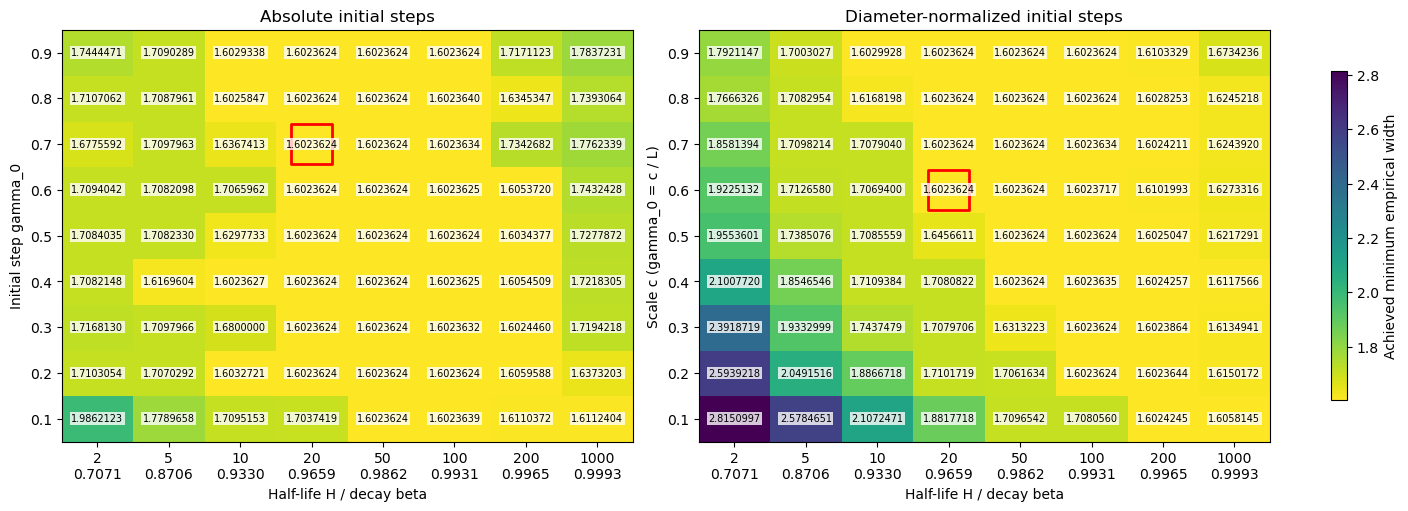

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, max(5.0, 0.32 * len(scale_grid) + 2.0)), constrained_layout=True)
vmin, vmax = ranking["minimum_width"].min(), ranking["minimum_width"].max()
for ax, rule in zip(axes, ("absolute", "diameter_normalized")):
    values = width_matrices[rule].to_numpy()
    image = ax.imshow(values, origin="lower", aspect="auto", cmap="viridis_r", vmin=vmin, vmax=vmax)
    ax.set_xticks(np.arange(len(half_life_grid)),
                  [f"{h:g}\n{np.exp2(-1.0/h):.4f}" for h in half_life_grid])
    ax.set_yticks(np.arange(len(scale_grid)), [f"{s:g}" for s in scale_grid])
    ax.set(xlabel="Half-life H / decay beta", ylabel="Initial step gamma_0" if rule == "absolute" else "Scale c (gamma_0 = c / L)",
           title="Absolute initial steps" if rule == "absolute" else "Diameter-normalized initial steps")
    for i in range(len(scale_grid)):
        for j in range(len(half_life_grid)):
            ax.text(j, i, f"{values[i, j]:.7f}", ha="center", va="center", fontsize=7,
                    bbox={"facecolor": "white", "alpha": 0.78, "edgecolor": "none", "pad": 1})
    best = best_by_rule.loc[best_by_rule["step_rule"] == rule].iloc[0]
    ax.scatter(np.flatnonzero(half_life_grid == best["half_life"])[0],
               np.flatnonzero(scale_grid == best["step_value"])[0],
               marker="s", s=850, facecolors="none", edgecolors="red", linewidths=2)
fig.colorbar(image, ax=axes, label="Achieved minimum empirical width", shrink=0.8)
save_figure(fig, "02_minimum_width_matrices", pdf_directory=PDF_DIR, image_directory=IMAGE_DIR)
plt.show()
plt.close(fig)


## Recovered coefficients for the selected fixed-path configurations

For each step rule, display the coefficients recovered from the selected grid result. The coefficient transformation is $\widehat\phi_j=-\widehat u_j/\widehat u_0$, as in the [thesis's coefficient-recovery remark](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex). This uses the directions already stored by the grid search. Coefficient errors are simulation diagnostics and do not enter the width-based selection. [Implementation](../ar_tools/tuning.py).

In [7]:
coefficient_rows = []
for choice in best_by_rule.to_dict("records"):
    for j in range(p):
        recovered = float(choice[f"estimated_phi_{j+1}"])
        coefficient_rows.append({
            "step_rule": choice["step_rule"], "lag": j+1, "true_phi": float(phi[j]),
            "estimated_phi": recovered, "error": float(recovered-phi[j]),
        })
coefficient_comparison = pd.DataFrame(coefficient_rows)
display(coefficient_comparison)

,step_rule,lag,true_phi,estimated_phi,error
0,absolute,1,0.6,0.632436,0.032436
1,absolute,2,-0.3,-0.337506,-0.037506
2,absolute,3,0.2,0.205886,0.005886
3,diameter_normalized,1,0.6,0.632436,0.032436
4,diameter_normalized,2,-0.3,-0.337506,-0.037506
5,diameter_normalized,3,0.2,0.205886,0.005886


## Experiment 1: selected configuration

The overall winner is printed below, and both rule winners are shown above. The complete grid and width matrices remain available as `ranking` and `width_matrices`. Settings and seeds remain in the settings cells above. Only PDF/PNG figures are exported.

This is a result for **one path and one starting direction**. Experiment 2 below selects one shared configuration across fresh realizations of the same model. The separate [sample-size and validation notebook](ar_tuning_sample_size_and_validation.ipynb) compares two sample sizes and evaluates a frozen schedule on fresh paths.

Ranks use full-precision widths. Candidates differing only at floating-point rounding precision should be read as attaining the same numerical width.


In [8]:
selected_on_grid_edge = bool(selected["on_grid_edge"])
print(f"Overall winner: {selected['step_rule']}, scale={selected['step_value']:g}, H={selected['half_life']:g}")
print(f"Actual gamma0={selected['gamma0']:.12g}; beta={selected['beta']:.12g}")
print(f"Smallest attained width={selected['minimum_width']:.12g}; grid edge={selected_on_grid_edge}")
print(f"PDF figures: {PDF_DIR}")


Overall winner: absolute, scale=0.7, H=20
Actual gamma0=0.7; beta=0.965936328925
Smallest attained width=1.60236238543; grid edge=False
PDF figures: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_unified_tuning_experiments/e5d3a96d1d49f6bd


## Experiment 2: fresh realizations, fixed coefficients and start

Keep $T=500$, $\phi=(0.6,-0.3,0.2)$, the innovation law, grids, budgets and **the exact same starting direction** from experiment 1. Only the innovation path changes. The setting **`number_of_realizations`** controls how many independent paths are drawn from a separate seed stream; all 144 labeled configurations use the same cloud within each replication. Each path gets its own actual diameter $L_r$. For normalized steps, keep $c$ fixed across paths and recompute $\gamma_{0,r}=c/L_r$.

**Selection rule:** on each path, record the smallest empirical width actually achieved by each configuration. To select one shared configuration, minimize the arithmetic mean of those achieved minimum widths across all paths:
$$\overline w(\theta)=\frac{1}{R}\sum_{r=1}^{R}\min_{t\,\text{evaluated}} w_{r,t}(\theta).$$
Here $R$ is `number_of_realizations`. Every path contributes equally. Exact ties in mean width are broken by mean evaluations, then rule, scale and half-life. The per-path final-width winners are also displayed as diagnostics. Coefficient recovery does not select the shared setting. This is the reporting and selection design used here. [Implementation](../ar_tools/tuning.py), `tune_fixed_ar_realizations` and `summarize_geometric_replications`.

All widths come from the projected subgradient runs. Selection uses no external optimum calculation, relative-gap target or success threshold. The original stopping rule uses a 2,000-iteration cap and patience 200. The smallest empirical width encountered before stopping is the function value. The absolute-gap co-winner count is shown in the final section. These paths form a tuning sample for the fixed model and start; fresh-path validation is provided in the [separate extension](ar_tuning_sample_size_and_validation.ipynb), and experiment 3 below varies the coefficient vectors.

In [9]:
realization_experiment = tune_fixed_ar_realizations(
    phi, T, initial_direction, scale_grid, half_life_grid,
    replications=number_of_realizations, process_seed=realization_process_seed,
    burnin=burnin, iterations=max_iterations, patience=patience,
    improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed,
    progress=True,
)
realization_results = pd.DataFrame(realization_experiment["results"])
realization_cases = pd.DataFrame(realization_experiment["cases"])
realization_ranking = pd.DataFrame(realization_experiment["ranking"])
realization_selected = realization_experiment["selected"]
realization_best_by_rule = realization_ranking.groupby("step_rule", sort=False).head(1).copy()
np.testing.assert_allclose(realization_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
assert len(realization_results) == number_of_realizations * 2 * len(scale_grid) * len(half_life_grid)
assert realization_results["total_evaluations"].between(1, max_iterations).all()
assert realization_cases["process_seed"].is_unique
assert process_seed not in realization_cases["process_seed"].tolist()
print(f"Completed {len(realization_cases)} fresh paths and {len(realization_results)} labeled runs.")
print(f"Original stopping rule: at most {max_iterations} evaluated iterations, patience={patience}.")
print(f"Fixed starting direction: {initial_direction}")
print("Per-path attained-width grid winners (diagnostics):")
display(realization_cases)
print("Shared-configuration ranking: smallest mean achieved minimum width.")
realization_summary_columns = [
    "rank", "step_rule", "step_value", "half_life", "beta", "replications",
    "mean_minimum_width", "median_minimum_width", "worst_minimum_width",
    "mean_evaluations", "gamma0_min", "gamma0_max",
]
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(realization_ranking[realization_summary_columns].head(15))
    print("Best shared configuration for each step rule:")
    display(realization_best_by_rule[realization_summary_columns])

Path 1/100, T=500: best achieved width=1.6259109893, L=5.31825, 144 schedules; 2.1s
Path 2/100, T=500: best achieved width=1.6107654881, L=4.61535, 144 schedules; 1.9s
Path 3/100, T=500: best achieved width=1.6136578771, L=5.24962, 144 schedules; 1.9s
Path 4/100, T=500: best achieved width=1.6177427651, L=4.86433, 144 schedules; 2.0s
Path 5/100, T=500: best achieved width=1.6049133695, L=5.04969, 144 schedules; 2.0s
Path 6/100, T=500: best achieved width=1.6065023152, L=5.11703, 144 schedules; 2.4s
Path 7/100, T=500: best achieved width=1.6098279369, L=4.95151, 144 schedules; 2.0s
Path 8/100, T=500: best achieved width=1.5942052418, L=4.56973, 144 schedules; 2.0s
Path 9/100, T=500: best achieved width=1.6251102567, L=5.43258, 144 schedules; 1.9s
Path 10/100, T=500: best achieved width=1.6765441132, L=4.82229, 144 schedules; 2.2s
Path 11/100, T=500: best achieved width=1.6158257142, L=4.6657, 144 schedules; 1.9s
Path 12/100, T=500: best achieved width=1.6180018221, L=5.48483, 144 schedu

,replication,T,process_seed,diameter,grid_best_width,grid_winner_candidate_id,grid_winner_step_rule,grid_winner_step_value,grid_winner_half_life,runtime_seconds
0,1,500,15285170486174312110,5.318248,1.625911,absolute_s03_h03,absolute,0.4,20.0,2.114819
1,2,500,2977048524731513747,4.615345,1.610765,absolute_s02_h02,absolute,0.3,10.0,1.864181
2,3,500,9700859109571484927,5.249617,1.613658,absolute_s03_h02,absolute,0.4,10.0,1.926940
3,4,500,10916039272464303899,4.864328,1.617743,absolute_s06_h02,absolute,0.7,10.0,1.997841
4,5,500,1062370734165657769,5.049694,1.604913,diameter_normalized_s04_h05,diameter_normalized,0.5,100.0,1.960021
...,...,...,...,...,...,...,...,...,...,...
95,96,500,5600466015318381656,4.463240,1.625103,absolute_s02_h02,absolute,0.3,10.0,1.778535
96,97,500,13729803690704503133,5.560254,1.604353,absolute_s05_h02,absolute,0.6,10.0,3.412778
97,98,500,9790441807068529897,5.128528,1.609351,absolute_s05_h04,absolute,0.6,50.0,1.904839
98,99,500,15627298590695882592,4.697970,1.609307,diameter_normalized_s02_h04,diameter_normalized,0.3,50.0,1.959255


,rank,step_rule,step_value,half_life,beta,replications,mean_minimum_width,median_minimum_width,worst_minimum_width,mean_evaluations,gamma0_min,gamma0_max
0,1,absolute,0.3,100.0,0.9930924954,100,1.6298115477,1.6178723425,1.8295987051,1682.58,0.3000000000,0.3000000000
1,2,absolute,0.2,50.0,0.9862327045,100,1.6301348409,1.6177275010,1.8295986865,1979.94,0.2000000000,0.2000000000
2,3,absolute,0.3,50.0,0.9862327045,100,1.6312813173,1.6182802919,1.8559853059,1995.69,0.3000000000,0.3000000000
3,4,diameter_normalized,0.9,100.0,0.9930924954,100,1.6321873878,1.6175702239,1.8704348302,1756.51,0.1485457181,0.2178995134
4,5,absolute,0.5,100.0,0.9930924954,100,1.6334192706,1.6180456101,1.8704349250,1587.03,0.5000000000,0.5000000000
5,6,absolute,0.7,50.0,0.9862327045,100,1.6339977194,1.6177275010,1.9051184697,1954.27,0.7000000000,0.7000000000
6,7,absolute,0.8,50.0,0.9862327045,100,1.6340768265,1.6176452877,1.8460315536,2000.00,0.8000000000,0.8000000000
7,8,absolute,0.6,50.0,0.9862327045,100,1.6355060657,1.6177275010,1.9021583861,1927.54,0.6000000000,0.6000000000
8,9,absolute,0.2,100.0,0.9930924954,100,1.6359826355,1.6178723222,1.8425945182,1670.09,0.2000000000,0.2000000000
9,10,absolute,0.4,100.0,0.9930924954,100,1.6360342435,1.6178840210,1.8931559818,1641.17,0.4000000000,0.4000000000


,rank,step_rule,step_value,half_life,beta,replications,mean_minimum_width,median_minimum_width,worst_minimum_width,mean_evaluations,gamma0_min,gamma0_max
0,1,absolute,0.3,100.0,0.9930924954,100,1.6298115477,1.6178723425,1.8295987051,1682.58,0.3000000000,0.3000000000
3,4,diameter_normalized,0.9,100.0,0.9930924954,100,1.6321873878,1.6175702239,1.8704348302,1756.51,0.1485457181,0.2178995134


## Mean achieved minimum widths across realizations

Each matrix entry is the mean achieved minimum width for that configuration across all paths. Lower values rank higher. Red squares mark the selected shared setting for each rule. The full per-path attained widths remain available in `realization_results`; the aggregate ranking is `realization_ranking`. All candidates share the same realized paths and fixed starting direction. [Summary implementation](../ar_tools/tuning.py), `summarize_geometric_replications`.

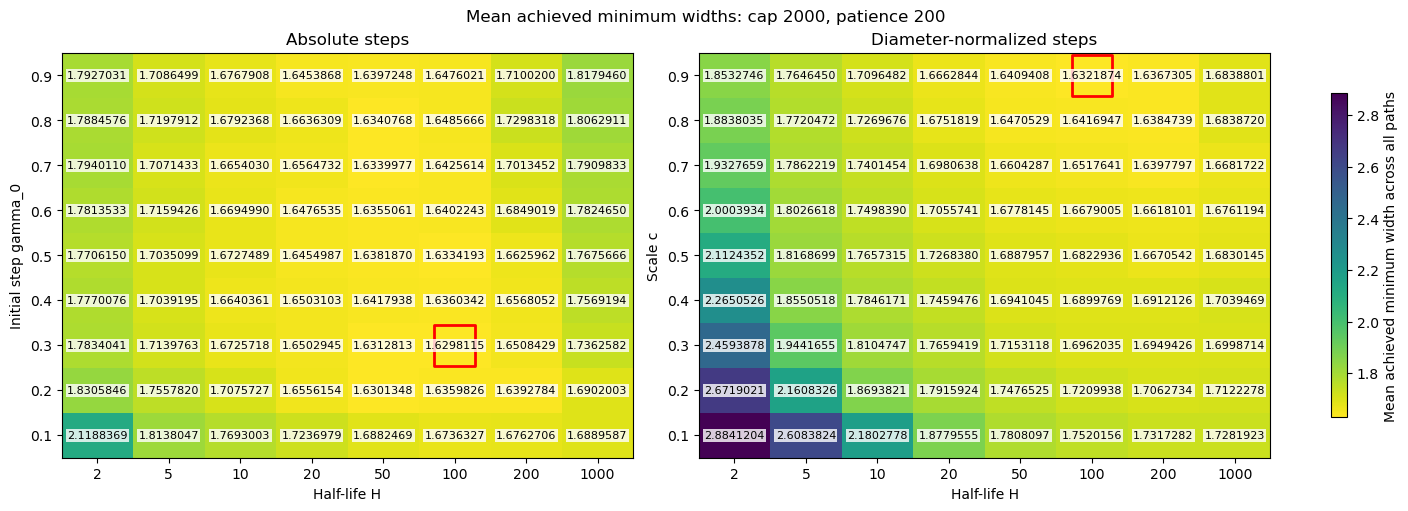

In [10]:
fig, realization_matrices = plot_tuning_matrices(
    realization_ranking, scale_grid, half_life_grid, metric="mean_minimum_width",
    title=f"Mean achieved minimum widths: cap {max_iterations}, patience {patience}",
    colorbar_label="Mean achieved minimum width across all paths",
    filename="04_realization_mean_minimum_widths", pdf_directory=PDF_DIR, image_directory=IMAGE_DIR,
)
plt.show()
plt.close(fig)

## Achieved widths of the two selected shared configurations

For each rule, apply its best shared configuration to all configured paths and show the achieved minimum width on every path. These values come directly from the grid runs; no optimum reference is plotted. The legend also gives the mean width used for selection. [Experiment implementation](../ar_tools/tuning.py), `tune_fixed_ar_realizations`.

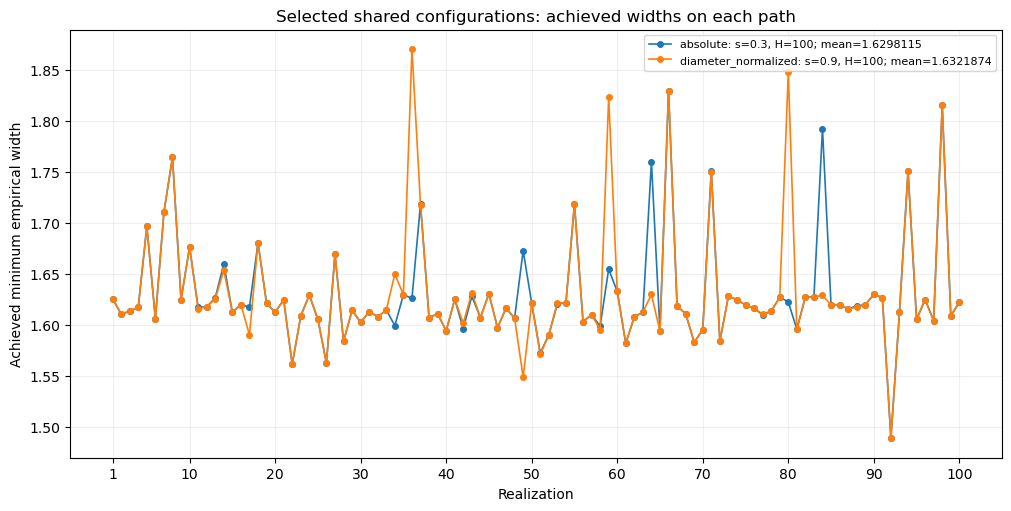

,absolute,diameter_normalized
replication,,
1,1.625911,1.625911
2,1.610766,1.611260
3,1.613658,1.613658
4,1.617743,1.617743
5,1.696732,1.696732
...,...,...
96,1.625103,1.625108
97,1.604354,1.604353
98,1.815569,1.815481


In [11]:
realization_selected_widths = pd.DataFrame(index=np.arange(1, number_of_realizations + 1))
realization_selected_widths.index.name = "replication"
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for choice in realization_best_by_rule.to_dict("records"):
    widths = realization_results.loc[
        realization_results["candidate_id"] == choice["candidate_id"],
    ].sort_values("replication")
    realization_selected_widths[choice["step_rule"]] = widths.set_index("replication")["minimum_width"]
    label = (f"{choice['step_rule']}: s={choice['step_value']:g}, H={choice['half_life']:g}; "
             f"mean={choice['mean_minimum_width']:.7f}")
    ax.plot(widths["replication"], widths["minimum_width"], marker="o", lw=1.2, ms=4, label=label)
ax.set(xlabel="Realization", ylabel="Achieved minimum empirical width",
       title="Selected shared configurations: achieved widths on each path",
       xticks=np.unique(np.linspace(1, number_of_realizations, min(11, number_of_realizations), dtype=int)))
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
save_figure(fig, "05_realization_selected_widths", pdf_directory=PDF_DIR, image_directory=IMAGE_DIR)
plt.show()
plt.close(fig)
display(realization_selected_widths)

## Experiment 2: selected common configuration and scope

The selected pair below has the **smallest mean achieved minimum width** over all configured tuning paths. For the normalized rule it is the pair $(c,H)$; the actual $\gamma_0=c/L_r$ varies with each realized cloud. Per-path winners remain available in `realization_cases`, and every candidate's attained width on every path is available in `realization_results`.

The complete results and ranking stay in this notebook and in memory. **Only PDF and PNG figures are exported; no JSON or CSV files are generated.** The separate [sample-size and validation notebook](ar_tuning_sample_size_and_validation.ipynb) performs fresh-path validation. Experiment 3 below varies coefficients; random-start sensitivity remains future work. This experiment measures sensitivity to innovations conditional on one fixed model and starting direction. [Experiment implementation](../ar_tools/tuning.py).

In [12]:
winner = realization_selected
print(f"Experiment 2 shared winner: {winner['step_rule']}, scale={winner['step_value']:g}, H={winner['half_life']:g}")
print(f"beta={winner['beta']:.12g}; actual gamma0 range=[{winner['gamma0_min']:.12g}, {winner['gamma0_max']:.12g}]")
print(f"Mean achieved minimum width over {number_of_realizations} paths: {winner['mean_minimum_width']:.12g}")
print(f"Median achieved minimum width: {winner['median_minimum_width']:.12g}")
print(f"Largest achieved minimum width: {winner['worst_minimum_width']:.12g}")
print("Selection uses achieved widths from the descent runs.")
print(f"PDF figures: {PDF_DIR}")

Experiment 2 shared winner: absolute, scale=0.3, H=100
beta=0.993092495437; actual gamma0 range=[0.3, 0.3]
Mean achieved minimum width over 100 paths: 1.62981154774
Median achieved minimum width: 1.6178723425
Largest achieved minimum width: 1.82959870506
Selection uses achieved widths from the descent runs.
PDF figures: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_unified_tuning_experiments/e5d3a96d1d49f6bd


## Win frequency: absolute-gap co-winners

On each of the **same configured realizations** from experiment 2, record each configuration's smallest achieved empirical width:
$$f_r(\theta)=\min_{t\,\mathrm{evaluated}}\hat w_{r,T}(u_{r,t}(\theta)).$$
Award a full **+1 to every configuration** satisfying
$$f_r(\theta)\le\min_{\eta\in\Theta}f_r(\eta)+\varepsilon,\qquad \varepsilon=10^{-8},$$
and count these credits over the configured paths:
$$N_\varepsilon(\theta)=\sum_{r=1}^R\mathbf{1}\!\left\{f_r(\theta)\le\min_{\eta\in\Theta}f_r(\eta)+\varepsilon\right\}.$$
The reference is the best achieved value among the tested configurations on the same path. Scores are compared at full precision against this absolute threshold. This is the defined counting rule for this experiment. [Counting implementation](../ar_tools/tuning.py), `summarize_configuration_wins(..., epsilon=...)`.

Change **`epsilon_win_tolerance`** in the settings cell to choose the absolute tolerance. Reuse `realization_results` from the **2,000-iteration cap / patience 200** descents above, with the same grid, starting direction and process seeds. The optimizer and mean-width ranking retain their existing settings. All qualifying configurations receive a full point regardless of speed; zero-win configurations remain in the ranking. Each configuration can receive at most $R$ points, while the total across configurations can exceed $R$. All configurations with the highest final count are displayed and highlighted. Equal counts are ordered by full-precision mean width, mean evaluations and labels for display only.

Tolerance-based comparison with a best achieved objective has precedent in [Moré and Wild, §2.1, equation (2.2)](https://optimization-online.org/wp-content/uploads/2008/01/1883.pdf#page=7); their tolerance is scaled by the objective reduction. The fixed absolute tolerance and full +1 credit used here are experimental choices. Tables stay in the notebook; only PDF/PNG figures are exported.

In [13]:
epsilon_win_experiment = summarize_configuration_wins(
    realization_results.to_dict("records"),
    score_key="minimum_width", epsilon=epsilon_win_tolerance,
)
epsilon_win_ranking = pd.DataFrame(epsilon_win_experiment["ranking"]).rename(
    columns={"rank": "win_rank", "mean_score": "mean_minimum_width"},
).merge(realization_ranking[["candidate_id", "rank", "gamma0_min", "gamma0_max"]].rename(
    columns={"rank": "mean_width_rank"},
), on="candidate_id", validate="one_to_one").sort_values("win_rank")
epsilon_win_leaders = epsilon_win_ranking.loc[
    epsilon_win_ranking["wins"] == epsilon_win_ranking["wins"].max()
].copy()
epsilon_win_best_by_rule = epsilon_win_ranking.loc[
    epsilon_win_ranking["wins"] == epsilon_win_ranking.groupby("step_rule")["wins"].transform("max")
].copy()
epsilon_win_winners = pd.DataFrame(epsilon_win_experiment["winners"])
epsilon_win_cases = pd.DataFrame(epsilon_win_experiment["case_summaries"])
assert epsilon_win_experiment["epsilon"] == epsilon_win_tolerance
assert epsilon_win_experiment["cases"] == number_of_realizations
assert epsilon_win_ranking["wins"].between(0, number_of_realizations).all()
assert epsilon_win_ranking["wins"].sum() == len(epsilon_win_winners) == epsilon_win_experiment["total_points"]
assert epsilon_win_cases["co_winners"].sum() == len(epsilon_win_winners)
assert not epsilon_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
assert (epsilon_win_winners["winning_score"] <= epsilon_win_winners["winning_threshold"]).all()

epsilon_win_columns = [
    "win_rank", "mean_width_rank", "step_rule", "step_value", "half_life", "beta",
    "wins", "win_rate", "mean_minimum_width", "mean_evaluations",
]

print(f"Tuning {number_of_realizations} paths: cap {max_iterations}, patience {patience}.")
print(f"+1 to EVERY configuration with achieved width <= path minimum + {epsilon_win_tolerance:g}.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(epsilon_win_ranking[epsilon_win_columns].head(15))
    print("All configurations with the highest absolute-gap win count:")
    display(epsilon_win_leaders[epsilon_win_columns])
    print("Highest counts within each step rule (including all ties):")
    display(epsilon_win_best_by_rule[epsilon_win_columns])
print(f"{epsilon_win_experiment['cases']} realizations; {epsilon_win_experiment['total_points']} full +1 credits; "
      f"{epsilon_win_experiment['tied_cases']} paths with multiple co-winners; "
      f"maximum {epsilon_win_experiment['maximum_co_winners']} co-winners on one path.")
for choice in epsilon_win_leaders.to_dict("records"):
    print(f"Absolute-gap win-count leader: {choice['step_rule']}, scale={choice['step_value']:g}, "
          f"H={choice['half_life']:g}, beta={choice['beta']:.12g}; "
          f"wins={int(choice['wins'])}/{number_of_realizations}.")

Tuning 100 paths: cap 2000, patience 200.
+1 to EVERY configuration with achieved width <= path minimum + 1e-08.
All configurations with the highest absolute-gap win count:
Highest counts within each step rule (including all ties):
100 realizations; 1669 full +1 credits; 84 paths with multiple co-winners; maximum 55 co-winners on one path.
Absolute-gap win-count leader: absolute, scale=0.7, H=50, beta=0.986232704493; wins=71/100.


,win_rank,mean_width_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_minimum_width,mean_evaluations
0,1,6,absolute,0.7,50.0,0.9862327045,71,0.71,1.6339977194,1954.27
1,2,7,absolute,0.8,50.0,0.9862327045,68,0.68,1.6340768265,2000.00
2,3,2,absolute,0.2,50.0,0.9862327045,67,0.67,1.6301348409,1979.94
3,4,8,absolute,0.6,50.0,0.9862327045,67,0.67,1.6355060657,1927.54
4,5,3,absolute,0.3,50.0,0.9862327045,66,0.66,1.6312813173,1995.69
5,6,12,absolute,0.5,50.0,0.9862327045,65,0.65,1.6381869588,1900.09
6,7,18,diameter_normalized,0.9,50.0,0.9862327045,65,0.65,1.6409408075,1962.40
7,8,20,absolute,0.4,50.0,0.9862327045,64,0.64,1.6417937596,1926.74
8,9,15,absolute,0.9,50.0,0.9862327045,63,0.63,1.6397248303,1941.57
9,10,24,diameter_normalized,0.8,50.0,0.9862327045,59,0.59,1.6470529045,2000.00


,win_rank,mean_width_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_minimum_width,mean_evaluations
0,1,6,absolute,0.7,50.0,0.9862327045,71,0.71,1.6339977194,1954.27


,win_rank,mean_width_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_minimum_width,mean_evaluations
0,1,6,absolute,0.7,50.0,0.9862327045,71,0.71,1.6339977194,1954.27
6,7,18,diameter_normalized,0.9,50.0,0.9862327045,65,0.65,1.6409408075,1962.40


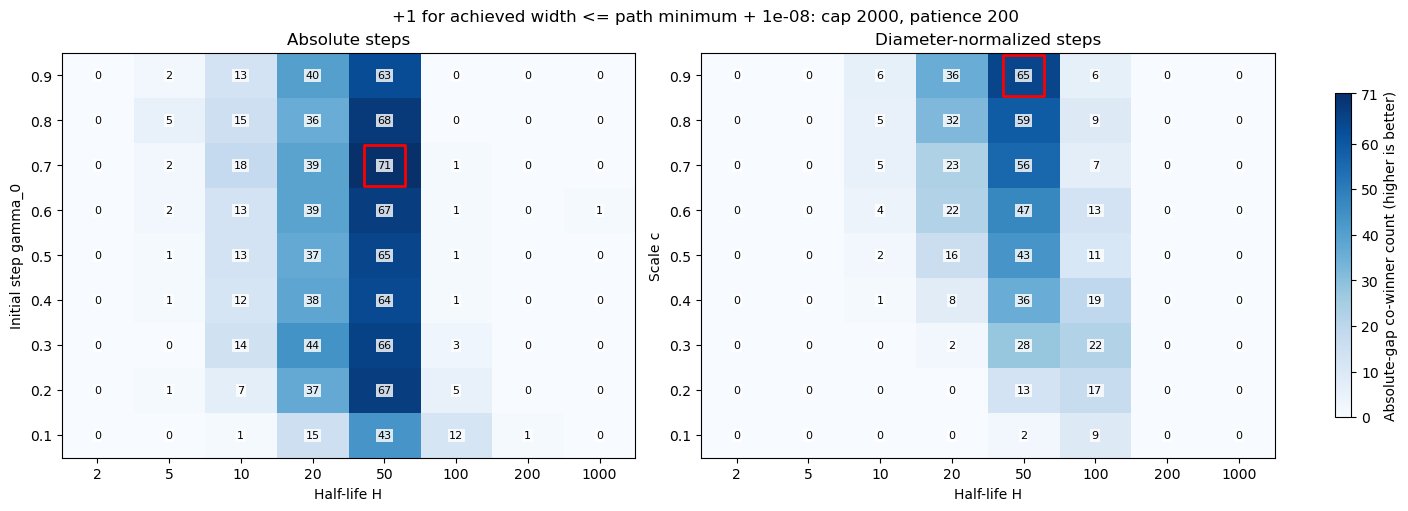

In [14]:
epsilon_win_figure_stem = f"07_epsilon_win_counts_eps_{epsilon_win_tolerance:g}"
fig, epsilon_win_matrices = plot_tuning_matrices(
    epsilon_win_ranking, scale_grid, half_life_grid, metric="wins", maximize=True, precision=0,
    title=f"+1 for achieved width <= path minimum + {epsilon_win_tolerance:g}: cap {max_iterations}, patience {patience}",
    colorbar_label="Absolute-gap co-winner count (higher is better)",
    filename=epsilon_win_figure_stem, pdf_directory=PDF_DIR, image_directory=IMAGE_DIR,
)
plt.show()
plt.close(fig)

## Experiment 3: 100 Jones-sampled AR(3) models, one fixed starting direction

For each model, draw a fresh coefficient vector with the existing [Jones sampler](../ar_tools/functions.py), then simulate one independent length-$T=500$ path with $U(-1,1)$ innovations after the same 2,000-observation burn-in. Jones's construction samples coefficients uniformly from the causal AR region through independent beta-distributed partial autocorrelations and a recursive transformation. [Jones (1987), pp. 134–138](https://doi.org/10.2307/2347544).

Use **the exact same `initial_direction` from experiment 1**, one start per descent, the same scale and half-life grids, **2,000 maximum iterations and patience 200**. Each model's one fixed point cloud is shared by all absolute and diameter-normalized candidates. Coefficient and innovation draws use separate seeded streams. Record each draw's coefficients, partial autocorrelations, companion spectral radius and seeds. The Jones draws are retained without a spectral-radius cutoff.

Select configurations by the **same absolute-gap co-winner rule**: award +1 to every achieved minimum width at most that model's best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). Mean achieved widths are reported separately as diagnostics. [Shared tuning and counting implementation](../ar_tools/tuning.py), `tune_jones_ar_realizations` and `summarize_configuration_wins`.

The variables below use the `jones_` prefix. Earlier experiment results remain available. Only PDF/PNG matrices are exported; all sampled models and numerical results remain in the notebook. No iteration plots or JSON/CSV data exports are generated.

Each progress line also reports the theoretical **population** minimum $2/\sqrt{1+\|\phi\|^2}$ and the signed empirical-minus-population gap. The final width diagnostic compares this reference with a known feasible direction on the same sample. These benchmarks do not enter the tuning score. [Thesis, Proposition `prop:minimum_width`](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex).

In [30]:
number_of_coefficient_realizations = 100  # CHANGE THIS: number of distinct Jones-sampled AR(3) models.
jones_coefficient_seed = 20261023
jones_process_seed = 20261024

jones_configuration = {
    "experiment": "jones_ar3_tuning", "T": int(T), "p": int(p),
    "replications": int(number_of_coefficient_realizations),
    "coefficient_sampling": "Jones1987_uniform_causal_AR3",
    "coefficient_seed": int(jones_coefficient_seed), "process_seed": int(jones_process_seed),
    "innovation_distribution": "Uniform(-1,1)", "burnin": int(burnin),
    "initial_direction": initial_direction.tolist(), "starts": 1, "optimizer_seed": int(optimizer_seed),
    "max_iterations": int(max_iterations), "patience": int(patience),
    "improvement_tolerance": float(improvement_tolerance),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "step_rules": ["absolute", "diameter_normalized"],
    "epsilon": float(epsilon_win_tolerance), "selection": "most_absolute_gap_co_winner_credits",
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py"]
    )).hexdigest(),
}
jones_run_id = hashlib.sha256(repr(sorted(jones_configuration.items())).encode()).hexdigest()[:16]
JONES_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
JONES_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
for directory in (JONES_PDF_DIR, JONES_IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Experiment 3: {number_of_coefficient_realizations} Jones AR(3) models, T={T}; cap {max_iterations}, patience {patience}.")
print(f"The same fixed u_0 for every candidate and model: {initial_direction}")

Experiment 3: 100 Jones AR(3) models, T=500; cap 2000, patience 200.
The same fixed u_0 for every candidate and model: [ 0.0469043  -0.81156153  0.31282302  0.49123275]


In [31]:
jones_experiment = tune_jones_ar_realizations(
    T, initial_direction, scale_grid, half_life_grid,
    replications=number_of_coefficient_realizations,
    coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
    burnin=burnin, iterations=max_iterations, patience=patience,
    improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed, progress=True,
)
jones_results = pd.DataFrame(jones_experiment["results"])
jones_cases = pd.DataFrame(jones_experiment["cases"])
jones_mean_ranking = pd.DataFrame(jones_experiment["ranking"])
jones_mean_selected = jones_experiment["selected"]
np.testing.assert_allclose(jones_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
assert len(jones_cases) == number_of_coefficient_realizations
assert len(jones_results) == number_of_coefficient_realizations * 2 * len(scale_grid) * len(half_life_grid)
assert jones_results["total_evaluations"].between(1, max_iterations).all()
assert jones_results["selected_start"].eq(1).all()
assert jones_cases["coefficient_seed"].is_unique and jones_cases["process_seed"].is_unique
assert jones_cases[["phi_1", "phi_2", "phi_3"]].drop_duplicates().shape[0] == number_of_coefficient_realizations
assert jones_cases["spectral_radius"].between(0, 1, inclusive="left").all()
print(f"Completed {len(jones_cases)} distinct models and {len(jones_results)} paired candidate runs.")
print("Separate diagnostic: ranking by mean achieved minimum empirical width.")
jones_mean_columns = [
    "rank", "step_rule", "step_value", "half_life", "beta", "replications",
    "mean_minimum_width", "median_minimum_width", "worst_minimum_width", "mean_evaluations",
]
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(jones_mean_ranking[jones_mean_columns].head(15))

Path 1/100, T=500: best achieved width=0.9942104448, population min=0.9997416721, empirical-population gap=-0.0055312274, L=18.4279, 144 schedules; 3.3s
Path 2/100, T=500: best achieved width=1.3146471407, population min=1.3221974789, empirical-population gap=-0.0075503381, L=11.4356, 144 schedules; 3.5s
Path 3/100, T=500: best achieved width=1.2281505150, population min=1.2728269262, empirical-population gap=-0.0446764112, L=7.60519, 144 schedules; 3.3s
Path 4/100, T=500: best achieved width=0.9716067099, population min=1.0059953689, empirical-population gap=-0.0343886591, L=9.61292, 144 schedules; 1.7s
Path 5/100, T=500: best achieved width=0.6635217138, population min=0.6690338627, empirical-population gap=-0.0055121489, L=20.0911, 144 schedules; 1.7s
Path 6/100, T=500: best achieved width=1.4382801546, population min=1.4681855298, empirical-population gap=-0.0299053752, L=6.44208, 144 schedules; 1.8s
Path 7/100, T=500: best achieved width=1.8430135441, population min=1.8539449890, 

,rank,step_rule,step_value,half_life,beta,replications,mean_minimum_width,median_minimum_width,worst_minimum_width,mean_evaluations
0,1,absolute,0.7,20.0,0.9659363289,100,1.4480985769,1.4456068481,2.2095684055,1245.16
1,2,absolute,0.6,20.0,0.9659363289,100,1.4502288669,1.4464907578,2.2216360915,1234.57
2,3,absolute,0.5,20.0,0.9659363289,100,1.4523233947,1.4498495545,2.2095684055,1222.28
3,4,absolute,0.8,20.0,0.9659363289,100,1.4617020801,1.4518229201,2.2095684055,1228.48
4,5,absolute,0.3,20.0,0.9659363289,100,1.4618491232,1.4618252212,2.2113490395,1221.55
5,6,absolute,0.4,20.0,0.9659363289,100,1.4619378798,1.4551874608,2.2095684055,1227.02
6,7,absolute,0.3,50.0,0.9862327045,100,1.4644734231,1.4452453929,2.2095684055,1698.40
7,8,absolute,0.7,10.0,0.9330329915,100,1.4664369406,1.4699393964,2.2095684055,717.99
8,9,absolute,0.9,20.0,0.9659363289,100,1.4665614082,1.4552643634,2.3345123402,1240.74
9,10,absolute,0.4,50.0,0.9862327045,100,1.4672628902,1.4516467262,2.2095684055,1744.64


In [32]:
jones_model_columns = [
    "replication", "phi_1", "phi_2", "phi_3", "pacf_1", "pacf_2", "pacf_3",
    "spectral_radius", "coefficient_seed", "process_seed", "diameter", "grid_best_width",
    "population_minimum_width", "grid_population_width_gap",
    "empirical_true_direction_width", "grid_empirical_true_direction_gap",
]
print("All sampled models and seeds:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.precision", 8):
    display(jones_cases[jones_model_columns])
print(f"Companion spectral-radius range: [{jones_cases['spectral_radius'].min():.8f}, "
      f"{jones_cases['spectral_radius'].max():.8f}].")

All sampled models and seeds:
Companion spectral-radius range: [0.41315948, 0.99908161].


,replication,phi_1,phi_2,phi_3,pacf_1,pacf_2,pacf_3,spectral_radius,coefficient_seed,process_seed,diameter,grid_best_width,population_minimum_width,grid_population_width_gap,empirical_true_direction_width,grid_empirical_true_direction_gap
0,1,1.35177242,-0.93644824,0.54575035,0.93321038,-0.28301092,0.54575035,0.96700120,16288181045755222347,10828296777479882745,18.42788011,0.99421044,0.99974167,-0.00553123,0.99941216,-0.00520171
1,2,-0.51381023,0.85629840,0.53926963,-0.40035132,0.81673115,0.53926963,0.96105313,11105578151043523248,12800449988372288735,11.43561617,1.31464714,1.32219748,-0.00755034,1.31832403,-0.00367689
2,3,0.77354339,-0.88980437,0.28085567,0.32857282,-0.73014402,0.28085567,0.86038735,10273860152015697191,10831720995082206158,7.60519150,1.22815052,1.27282693,-0.04467641,1.26717011,-0.03901959
3,4,1.35689922,-0.96486037,0.42465741,0.78387565,-0.47414804,0.42465741,0.81263086,6366326135738863003,7601784367034788820,9.61291724,0.97160671,1.00599537,-0.03438866,0.99729807,-0.02569136
4,5,-1.95035008,-1.87431396,-0.78708720,-0.66012720,-0.89152159,-0.78708720,0.97114441,7551298518433996483,8340308198013301003,20.09107035,0.66352171,0.66903386,-0.00551215,0.66656752,-0.00304581
5,6,0.89812834,-0.20595791,-0.08127461,0.71903908,-0.28080784,-0.08127461,0.64671927,11591331125286168226,12385543695779430734,6.44207850,1.43828015,1.46818553,-0.02990538,1.46534040,-0.02706025
6,7,0.23994370,0.25585116,-0.20182893,0.25045908,0.21623176,-0.20182893,0.64399523,290960773894637450,13964900212507695027,4.25717633,1.84301354,1.85394499,-0.01093144,1.84667460,-0.00366105
7,8,0.24301261,0.53968770,-0.45344962,-0.00468243,0.54066299,-0.45344962,0.90568494,16971434785173947726,1306502758028956009,5.18810372,1.59371816,1.60337216,-0.00965400,1.59728726,-0.00356910
8,9,-0.50776003,0.69680754,0.66191736,-0.23132148,0.64199069,0.66191736,0.95276611,6561579481862075310,16276280573437201634,7.31020382,1.32851127,1.35410651,-0.02559524,1.34723476,-0.01872349
9,10,0.65218559,0.50724698,-0.79497548,0.65641183,-0.03050039,-0.79497548,0.94082046,11743614143701613157,17073338895397600117,10.92958601,1.29844404,1.31458618,-0.01614214,1.30870869,-0.01026465


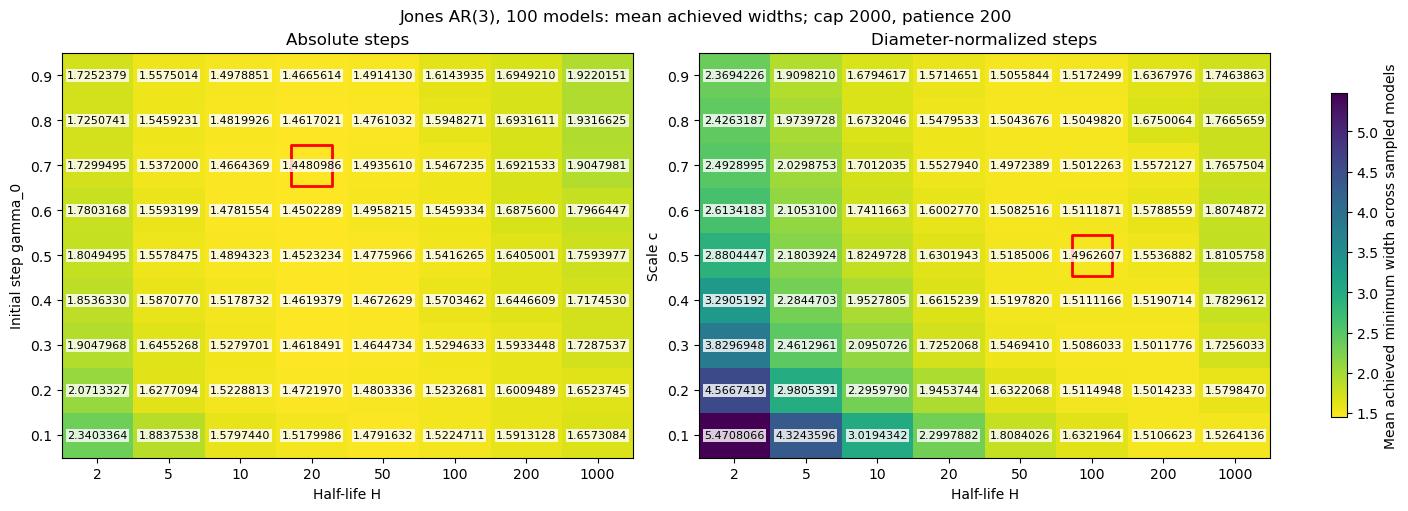

In [33]:
fig, jones_mean_matrices = plot_tuning_matrices(
    jones_mean_ranking, scale_grid, half_life_grid, metric="mean_minimum_width",
    title=f"Jones AR(3), {number_of_coefficient_realizations} models: mean achieved widths; cap {max_iterations}, patience {patience}",
    colorbar_label="Mean achieved minimum width across sampled models",
    filename="01_jones_mean_minimum_widths", pdf_directory=JONES_PDF_DIR, image_directory=JONES_IMAGE_DIR,
)
plt.show()
plt.close(fig)

In [34]:
jones_win_experiment = summarize_configuration_wins(
    jones_results.to_dict("records"), score_key="minimum_width", epsilon=epsilon_win_tolerance,
)
jones_win_ranking = pd.DataFrame(jones_win_experiment["ranking"]).rename(
    columns={"rank": "win_rank", "mean_score": "mean_minimum_width"},
).merge(jones_mean_ranking[["candidate_id", "rank", "gamma0_min", "gamma0_max"]].rename(
    columns={"rank": "mean_width_rank"},
), on="candidate_id", validate="one_to_one").sort_values("win_rank")
jones_win_leaders = jones_win_ranking.loc[
    jones_win_ranking["wins"] == jones_win_ranking["wins"].max()
].copy()
jones_win_best_by_rule = jones_win_ranking.loc[
    jones_win_ranking["wins"] == jones_win_ranking.groupby("step_rule")["wins"].transform("max")
].copy()
jones_win_winners = pd.DataFrame(jones_win_experiment["winners"])
assert jones_win_experiment["cases"] == number_of_coefficient_realizations
assert jones_win_ranking["wins"].between(0, number_of_coefficient_realizations).all()
assert jones_win_ranking["wins"].sum() == len(jones_win_winners) == jones_win_experiment["total_points"]
assert not jones_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
assert (jones_win_winners["winning_score"] <= jones_win_winners["winning_threshold"]).all()
jones_win_columns = [
    "win_rank", "mean_width_rank", "step_rule", "step_value", "half_life", "beta",
    "wins", "win_rate", "mean_minimum_width", "mean_evaluations",
]
print(f"Experiment 3 selection: +1 to every configuration within {epsilon_win_tolerance:g} of each model's best achieved width.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(jones_win_ranking[jones_win_columns].head(15))
    print("All configurations with the highest win count:")
    display(jones_win_leaders[jones_win_columns])
    print("Highest counts within each step rule (including all ties):")
    display(jones_win_best_by_rule[jones_win_columns])
print(f"{jones_win_experiment['cases']} models; {jones_win_experiment['total_points']} full +1 credits; "
      f"{jones_win_experiment['tied_cases']} models with multiple co-winners.")

Experiment 3 selection: +1 to every configuration within 1e-08 of each model's best achieved width.
All configurations with the highest win count:
Highest counts within each step rule (including all ties):
100 models; 1251 full +1 credits; 60 models with multiple co-winners.


,win_rank,mean_width_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_minimum_width,mean_evaluations
0,1,7,absolute,0.3,50.0,0.9862327045,40,0.40,1.4644734231,1698.40
1,2,13,absolute,0.5,50.0,0.9862327045,40,0.40,1.4775966472,1730.66
2,3,20,absolute,0.7,50.0,0.9862327045,40,0.40,1.4935609929,1650.16
3,4,10,absolute,0.4,50.0,0.9862327045,39,0.39,1.4672628902,1744.64
4,5,15,absolute,0.1,50.0,0.9862327045,38,0.38,1.4791631604,1832.07
5,6,12,absolute,0.8,50.0,0.9862327045,37,0.37,1.4761032029,1614.23
6,7,19,absolute,0.9,50.0,0.9862327045,37,0.37,1.4914130357,1566.04
7,8,21,absolute,0.6,50.0,0.9862327045,37,0.37,1.4958215422,1639.70
8,9,40,diameter_normalized,0.5,50.0,0.9862327045,37,0.37,1.5185005521,1954.16
9,10,42,diameter_normalized,0.4,50.0,0.9862327045,37,0.37,1.5197820069,2000.00


,win_rank,mean_width_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_minimum_width,mean_evaluations
0,1,7,absolute,0.3,50.0,0.9862327045,40,0.4,1.4644734231,1698.40
1,2,13,absolute,0.5,50.0,0.9862327045,40,0.4,1.4775966472,1730.66
2,3,20,absolute,0.7,50.0,0.9862327045,40,0.4,1.4935609929,1650.16


,win_rank,mean_width_rank,step_rule,step_value,half_life,beta,wins,win_rate,mean_minimum_width,mean_evaluations
0,1,7,absolute,0.3,50.0,0.9862327045,40,0.40,1.4644734231,1698.40
1,2,13,absolute,0.5,50.0,0.9862327045,40,0.40,1.4775966472,1730.66
2,3,20,absolute,0.7,50.0,0.9862327045,40,0.40,1.4935609929,1650.16
8,9,40,diameter_normalized,0.5,50.0,0.9862327045,37,0.37,1.5185005521,1954.16
9,10,42,diameter_normalized,0.4,50.0,0.9862327045,37,0.37,1.5197820069,2000.00


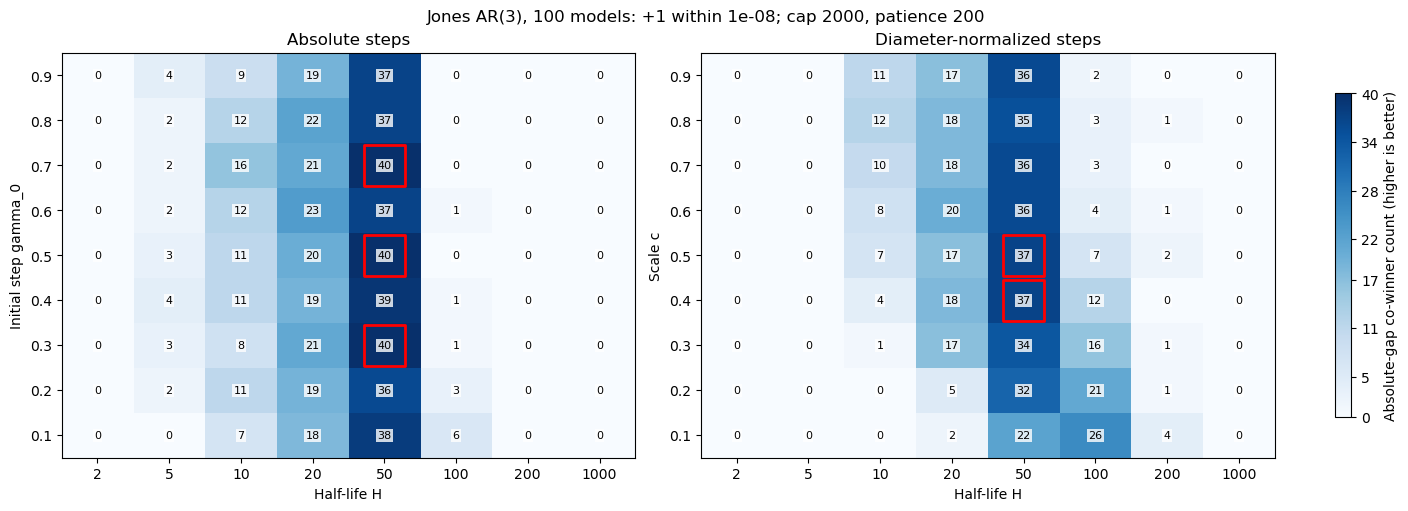

In [35]:
jones_win_figure_stem = f"02_jones_win_counts_eps_{epsilon_win_tolerance:g}"
fig, jones_win_matrices = plot_tuning_matrices(
    jones_win_ranking, scale_grid, half_life_grid, metric="wins", maximize=True, precision=0,
    title=f"Jones AR(3), {number_of_coefficient_realizations} models: +1 within {epsilon_win_tolerance:g}; cap {max_iterations}, patience {patience}",
    colorbar_label="Absolute-gap co-winner count (higher is better)",
    filename=jones_win_figure_stem, pdf_directory=JONES_PDF_DIR, image_directory=JONES_IMAGE_DIR,
)
plt.show()
plt.close(fig)

In [36]:
print("Experiment 3 winners under the absolute-gap win-count rule:")
for choice in jones_win_leaders.to_dict("records"):
    print(f"{choice['step_rule']}: scale={choice['step_value']:g}, H={choice['half_life']:g}, "
          f"beta={choice['beta']:.12g}; {int(choice['wins'])}/{number_of_coefficient_realizations} model wins.")
    print(f"Actual gamma0 range across models: [{choice['gamma0_min']:.12g}, {choice['gamma0_max']:.12g}].")
print(f"Separate mean-width winner: {jones_mean_selected['step_rule']}, "
      f"scale={jones_mean_selected['step_value']:g}, H={jones_mean_selected['half_life']:g}; "
      f"mean achieved width={jones_mean_selected['mean_minimum_width']:.12g}.")
print(f"One fixed u_0 throughout: {initial_direction}")
print(f"PDF matrices: {JONES_PDF_DIR}")

Experiment 3 winners under the absolute-gap win-count rule:
absolute: scale=0.3, H=50, beta=0.986232704493; 40/100 model wins.
Actual gamma0 range across models: [0.3, 0.3].
absolute: scale=0.5, H=50, beta=0.986232704493; 40/100 model wins.
Actual gamma0 range across models: [0.5, 0.5].
absolute: scale=0.7, H=50, beta=0.986232704493; 40/100 model wins.
Actual gamma0 range across models: [0.7, 0.7].
Separate mean-width winner: absolute, scale=0.7, H=20; mean achieved width=1.44809857689.
One fixed u_0 throughout: [ 0.0469043  -0.81156153  0.31282302  0.49123275]
PDF matrices: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_unified_tuning_experiments/jones_914c846ae728b160


## Experiment 3: coefficient-recovery failures

Recover $\widehat\phi=-\widehat u_{1:}/\widehat u_0$ from each run's returned best-width direction. Apply the same diagnostic as the [stationarity-triggered restart experiment](../ar3_conditional_restarts_2000_200.ipynb): a finite estimate fails the stationarity check when its companion spectral radius is at least one. Undefined or nonfinite estimates are counted separately. [Coefficient transformation and stationarity check](../ar_tools/functions.py).

Also report per-vector coefficient MSE $\frac13\sum_{j=1}^3(\widehat\phi_j-\phi_j)^2>1$, the large-error diagnostic used in the earlier restart study. This is a separate error threshold, not the stationarity test. Both are post-fit diagnostics: widths, parameter rankings, starts and stopping settings remain unchanged. The small-denominator mechanism was examined in the [earlier failure-tracking notebook](../ar3_failed_coefficient_tracking.ipynb); a failed stationarity check alone does not establish the mechanism of every error.

Report all grid runs, each leading shared configuration, and the single lowest-width grid result on each of the 100 model paths. These are different denominators. Tables stay in the notebook; no files or plots are exported.

In [37]:
jones_coefficient_diagnostics = jones_results.copy()
jones_directions = jones_coefficient_diagnostics[[f"u_{j}" for j in range(embedding_dimension)]].to_numpy(dtype=float)
jones_true_coefficients = jones_coefficient_diagnostics[[f"phi_{j}" for j in range(1, p+1)]].to_numpy(dtype=float)
with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
    jones_recovered_coefficients = -jones_directions[:, 1:] / jones_directions[:, :1]
    jones_coefficient_mse = np.mean((jones_recovered_coefficients - jones_true_coefficients)**2, axis=1)
jones_coefficients_finite = np.isfinite(jones_recovered_coefficients).all(axis=1)
jones_recovered_radii = np.full(len(jones_coefficient_diagnostics), np.nan)
for index in np.flatnonzero(jones_coefficients_finite):
    jones_recovered_radii[index] = np.max(np.abs(is_stationary(jones_recovered_coefficients[index])[1]))
for j in range(p):
    jones_coefficient_diagnostics[f"estimated_phi_{j+1}"] = jones_recovered_coefficients[:, j]
jones_coefficient_diagnostics["abs_first_direction_coordinate"] = np.abs(jones_directions[:, 0])
jones_coefficient_diagnostics["coefficient_mse"] = jones_coefficient_mse
jones_coefficient_diagnostics["estimated_spectral_radius"] = jones_recovered_radii
jones_coefficient_diagnostics["undefined_coefficients"] = ~jones_coefficients_finite
jones_coefficient_diagnostics["nonstationary_estimate"] = jones_coefficients_finite & (jones_recovered_radii >= 1)
jones_coefficient_diagnostics["failed_stationarity_check"] = (
    jones_coefficient_diagnostics["undefined_coefficients"] | jones_coefficient_diagnostics["nonstationary_estimate"]
)
jones_coefficient_diagnostics["coefficient_mse_above_1"] = jones_coefficients_finite & (jones_coefficient_mse > 1)

jones_failure_by_configuration = jones_coefficient_diagnostics.groupby(
    ["candidate_id", "step_rule", "step_value", "half_life", "beta"], as_index=False,
).agg(
    runs=("replication", "size"), nonstationary_estimates=("nonstationary_estimate", "sum"),
    undefined_coefficients=("undefined_coefficients", "sum"),
    failed_stationarity_checks=("failed_stationarity_check", "sum"),
    coefficient_mse_above_1=("coefficient_mse_above_1", "sum"),
    maximum_coefficient_mse=("coefficient_mse", "max"),
    minimum_abs_first_coordinate=("abs_first_direction_coordinate", "min"),
)
jones_failure_counts = pd.DataFrame([{
    "runs": len(jones_coefficient_diagnostics),
    "nonstationary_estimates": int(jones_coefficient_diagnostics["nonstationary_estimate"].sum()),
    "undefined_coefficients": int(jones_coefficient_diagnostics["undefined_coefficients"].sum()),
    "coefficient_mse_above_1": int(jones_coefficient_diagnostics["coefficient_mse_above_1"].sum()),
}])
jones_leading_failure_ids = list(dict.fromkeys([
    *jones_win_leaders["candidate_id"].tolist(), jones_mean_selected["candidate_id"],
]))
jones_leading_coefficient_failures = jones_failure_by_configuration.set_index("candidate_id").loc[
    jones_leading_failure_ids
].reset_index()
jones_grid_winner_coefficients = jones_cases[["replication", "T", "grid_winner_candidate_id"]].rename(
    columns={"grid_winner_candidate_id": "candidate_id"},
).merge(jones_coefficient_diagnostics, on=["replication", "T", "candidate_id"], validate="one_to_one")
assert len(jones_grid_winner_coefficients) == number_of_coefficient_realizations
assert jones_failure_by_configuration["runs"].eq(number_of_coefficient_realizations).all()
assert np.isfinite(jones_coefficient_diagnostics["minimum_width"]).all()
print("All grid runs (every tested configuration, including poor settings):")
with pd.option_context("display.max_columns", None):
    display(jones_failure_counts)
print("Win-count leaders, followed by the separate mean-width winner:")
with pd.option_context("display.max_columns", None, "display.precision", 8):
    display(jones_leading_coefficient_failures)
print(f"Selecting the single lowest achieved width across the entire grid on each model: "
      f"{int(jones_grid_winner_coefficients['nonstationary_estimate'].sum())}/{number_of_coefficient_realizations} nonstationary estimates; "
      f"{int(jones_grid_winner_coefficients['undefined_coefficients'].sum())} undefined estimates; "
      f"{int(jones_grid_winner_coefficients['coefficient_mse_above_1'].sum())} with coefficient MSE > 1.")

All grid runs (every tested configuration, including poor settings):
Win-count leaders, followed by the separate mean-width winner:
Selecting the single lowest achieved width across the entire grid on each model: 11/100 nonstationary estimates; 0 undefined estimates; 11 with coefficient MSE > 1.


,runs,nonstationary_estimates,undefined_coefficients,coefficient_mse_above_1
0,14400,6426,0,5402


,candidate_id,step_rule,step_value,half_life,beta,runs,nonstationary_estimates,undefined_coefficients,failed_stationarity_checks,coefficient_mse_above_1,maximum_coefficient_mse,minimum_abs_first_coordinate
0,absolute_s02_h04,absolute,0.3,50.0,0.98623270,100,36,0,36,35,1.14990672e+07,0.00017028
1,absolute_s04_h04,absolute,0.5,50.0,0.98623270,100,38,0,38,35,7.75252908e+04,0.00207394
2,absolute_s06_h04,absolute,0.7,50.0,0.98623270,100,40,0,40,36,7.75252908e+04,0.00207394
3,absolute_s06_h03,absolute,0.7,20.0,0.96593633,100,34,0,34,32,7.75252909e+04,0.00207394


## Experiment 3: achieved widths versus the population minimum

For each causal AR(3) model with innovations on $[-1,1]$, use the population reference from the [thesis, Proposition `prop:minimum_width`](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex):
$$m_{\mathrm{pop}}=\frac{2}{\sqrt{1+\|\phi\|^2}}.$$
The progress output and model table show the **signed discrepancy** $f_r(\theta)-m_{\mathrm{pop}}$. This compares an attained empirical width with a population minimum; it is not the optimization gap for the finite cloud and can be negative. The population reference is a diagnostic only.

For a comparison within the same empirical objective, compute the feasible true-coefficient direction
$$u_\phi=\frac{(1,-\phi_1,-\phi_2,-\phi_3)}{\sqrt{1+\|\phi\|^2}}$$
and its empirical width $\hat w_r(u_\phi)$. By the definition of an empirical minimum, $\hat m_r\le\hat w_r(u_\phi)$. Hence
$$f_r(\theta)-\hat m_r\;\ge\;f_r(\theta)-\hat w_r(u_\phi).$$
This inequality is a direct feasibility argument. A positive difference exceeding `epsilon_win_tolerance` demonstrates that the search returned a width worse than an available direction. The nonnegative part of this difference is a lower bound on empirical suboptimality. A smaller width does not establish that the empirical global minimum was reached.

The tables report both discrepancies for all 100 model paths and for the leading configurations. Counts of widths above either benchmark use the existing absolute tolerance $10^{-8}$; no extra numerical global optimization, coefficient-based filtering, or change in the tuning ranking is introduced. The phrase “failed completely” has no additional numerical cutoff here; the reported gaps show the size of each miss.

In [38]:
jones_width_columns = [
    "replication", "grid_best_width", "population_minimum_width", "grid_population_width_gap",
    "empirical_true_direction_width", "grid_empirical_true_direction_gap",
]
jones_width_diagnostics = jones_cases[jones_width_columns].copy()
jones_width_diagnostics["grid_population_gap_percent"] = (
    100 * jones_width_diagnostics["grid_population_width_gap"] / jones_width_diagnostics["population_minimum_width"]
)
jones_width_diagnostics["empirical_suboptimality_lower_bound"] = (
    jones_width_diagnostics["grid_empirical_true_direction_gap"].clip(lower=0)
)
jones_width_diagnostics["above_population_benchmark"] = (
    jones_width_diagnostics["grid_population_width_gap"] > epsilon_win_tolerance
)
jones_width_diagnostics["worse_than_known_feasible_direction"] = (
    jones_width_diagnostics["grid_empirical_true_direction_gap"] > epsilon_win_tolerance
)
jones_width_summary = pd.DataFrame([{
    "models": len(jones_width_diagnostics),
    "grid_winners_above_population_minimum": int(jones_width_diagnostics["above_population_benchmark"].sum()),
    "grid_winners_worse_than_known_feasible_direction": int(jones_width_diagnostics["worse_than_known_feasible_direction"].sum()),
    "maximum_empirical_minus_population_gap": jones_width_diagnostics["grid_population_width_gap"].max(),
    "maximum_empirical_minus_population_percent": jones_width_diagnostics["grid_population_gap_percent"].max(),
    "maximum_empirical_suboptimality_lower_bound": jones_width_diagnostics["empirical_suboptimality_lower_bound"].max(),
}])
jones_run_width_diagnostics = jones_results.assign(
    above_population_benchmark=jones_results["population_width_gap"] > epsilon_win_tolerance,
    worse_than_known_feasible_direction=jones_results["empirical_true_direction_gap"] > epsilon_win_tolerance,
    population_gap_percent=100*jones_results["population_width_gap"]/jones_results["population_minimum_width"],
)
jones_width_by_configuration = jones_run_width_diagnostics.groupby(
    ["candidate_id", "step_rule", "step_value", "half_life"], as_index=False,
).agg(
    runs=("replication", "size"),
    above_population_benchmark=("above_population_benchmark", "sum"),
    worse_than_known_feasible_direction=("worse_than_known_feasible_direction", "sum"),
    maximum_population_gap_percent=("population_gap_percent", "max"),
)
jones_leading_width_diagnostics = jones_width_by_configuration.set_index("candidate_id").loc[
    jones_leading_failure_ids
].reset_index()
print("Best achieved width across the grid on each model: benchmark comparison.")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(jones_width_summary)
    print("Leading shared configurations (win-count leaders, then mean-width winner):")
    display(jones_leading_width_diagnostics)
    print("Ten largest signed empirical-minus-population gaps among model-wise grid winners:")
    display(jones_width_diagnostics.sort_values("grid_population_width_gap", ascending=False).head(10))
print(f"{int(jones_width_diagnostics['above_population_benchmark'].sum())}/{number_of_coefficient_realizations} "
      f"model-wise grid winners are above the theoretical population minimum by more than {epsilon_win_tolerance:g}.")
print(f"{int(jones_width_diagnostics['worse_than_known_feasible_direction'].sum())}/{number_of_coefficient_realizations} "
      f"model-wise grid winners are worse than the known feasible true-coefficient direction by more than {epsilon_win_tolerance:g}.")

Best achieved width across the grid on each model: benchmark comparison.
Leading shared configurations (win-count leaders, then mean-width winner):
Ten largest signed empirical-minus-population gaps among model-wise grid winners:
5/100 model-wise grid winners are above the theoretical population minimum by more than 1e-08.
6/100 model-wise grid winners are worse than the known feasible true-coefficient direction by more than 1e-08.


,models,grid_winners_above_population_minimum,grid_winners_worse_than_known_feasible_direction,maximum_empirical_minus_population_gap,maximum_empirical_minus_population_percent,maximum_empirical_suboptimality_lower_bound
0,100,5,6,0.2007899042,13.2311468358,0.2034859497


,candidate_id,step_rule,step_value,half_life,runs,above_population_benchmark,worse_than_known_feasible_direction,maximum_population_gap_percent
0,absolute_s02_h04,absolute,0.3,50.0,100,43,44,95.7106140847
1,absolute_s04_h04,absolute,0.5,50.0,100,43,43,71.6107666640
2,absolute_s06_h04,absolute,0.7,50.0,100,43,43,132.5802822190
3,absolute_s06_h03,absolute,0.7,20.0,100,38,40,21.9433161410


,replication,grid_best_width,population_minimum_width,grid_population_width_gap,empirical_true_direction_width,grid_empirical_true_direction_gap,grid_population_gap_percent,empirical_suboptimality_lower_bound,above_population_benchmark,worse_than_known_feasible_direction
48,49,1.8679704564,1.6671805521,0.2007899042,1.6644845067,0.2034859497,12.0436808112,0.2034859497,True,True
70,71,1.6941677794,1.4962029678,0.1979648116,1.4947096322,0.1994581473,13.2311468358,0.1994581473,True,True
94,95,1.6065652321,1.5391495940,0.0674156381,1.5352104742,0.0713547579,4.3800575584,0.0713547579,True,True
97,98,1.5457207462,1.4952077865,0.0505129597,1.4909126592,0.0548080869,3.3783237425,0.0548080869,True,True
39,40,1.6732865963,1.6659562199,0.0073303764,1.6599460845,0.0133405118,0.4400101481,0.0133405118,True,True
63,64,0.7914474456,0.7951516386,-0.0037041929,0.7939572098,-0.0025097641,-0.4658473629,0.0000000000,False,False
31,32,0.7068305326,0.7106646309,-0.0038340982,0.7088980716,-0.0020675390,-0.5395087994,0.0000000000,False,False
58,59,1.3523689840,1.3567065642,-0.0043375802,1.3551565536,-0.0027875695,-0.3197139519,0.0000000000,False,False
91,92,1.0594801524,1.0639421081,-0.0044619557,1.0616435762,-0.0021634238,-0.4193795549,0.0000000000,False,False
30,31,1.6487307041,1.6532215094,-0.0044908053,1.6518916745,-0.0031609704,-0.2716396609,0.0000000000,False,False
